# BRIDGE-Net | Dataset statistical analysis
Standalone notebook for the reviewed preprocessing pipeline. Run cells in order. No original data are modified. Default analysis is **training only** to avoid using held-out labels for architectural decisions. Split/site inventory counts are descriptive; enable held-out label summaries only for reporting, not tuning. Slice counts are not patient prevalence. Unknown annotations are not negatives.

In [1]:
%pip install numpy pandas matplotlib tqdm pillow


[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display
from PIL import Image
DATA = Path('bridge_preprocessed_baseline').resolve()
REPORT = DATA.parent / (DATA.name + '_statistics')
INCLUDE_HELDOUT_LABEL_SUMMARIES = False
MASK_FOLDER = 'multilabel_masks'  # processed masks; raw_masks for original-resolution sensitivity analysis
REPORT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi':120,'savefig.dpi':300,'font.size':10})
def save_table(df,name):
    df.to_csv(REPORT/f'{name}.csv',index=False)
    display(df.head(25))
def finish(fig,name):
    fig.tight_layout(); fig.savefig(REPORT/f'{name}.png',bbox_inches='tight'); fig.savefig(REPORT/f'{name}.svg',bbox_inches='tight'); plt.show(); plt.close(fig)
def divide(a,b):
    a,b=np.broadcast_arrays(np.asarray(a,float),np.asarray(b,float))
    return np.divide(a,b,out=np.full(a.shape,np.nan),where=b>0)


/Users/bash/Documents/Phd code/bash_phd/labelbox_export_segmentation/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Load and validate the actual preprocessing outputs

In [3]:
for f in ['class_mapping.json','split_manifest.csv']:
    if not (DATA/f).is_file(): raise FileNotFoundError(DATA/f)
classes=json.loads((DATA/'class_mapping.json').read_text())
names=sorted(classes,key=classes.get); K=len(names)
assert sorted(classes.values())==list(range(K)), 'Invalid channel mapping'
manifest=pd.read_csv(DATA/'split_manifest.csv',dtype=str)
required=['sample_id','patient_id','source_project','split','image_filename']
assert set(required)<=set(manifest.columns)
assert manifest[required].notna().all().all() and manifest[required].apply(lambda c:c.str.strip().ne('').all()).all()
assert not manifest.sample_id.duplicated().any()
assert set(manifest.split)=={'train','val','test'}
assert manifest.groupby('patient_id').split.nunique().max()==1
assert manifest.sample_id.map(lambda s: Path(s).name==s and s not in ['.','..']).all()
if (DATA/'hashes.csv').exists():
    h=manifest.merge(pd.read_csv(DATA/'hashes.csv',dtype=str)[['sample_id','sha256_pixels']],on='sample_id',how='left',validate='one_to_one')
    assert h.sha256_pixels.notna().all() and h.groupby('sha256_pixels').split.nunique().max()==1, 'Duplicate leakage or missing hashes'
else: print('Warning: exact-duplicate leakage not independently checked; hashes.csv missing')
print(f'{len(manifest):,} slices | {manifest.patient_id.nunique():,} patient IDs | {K} channels')
print('Dataset:',DATA)


3,998 slices | 3,998 patient IDs | 23 channels
Dataset: /Users/bash/Documents/Phd code/bash_phd/labelbox_export_segmentation/bridge_preprocessed_baseline


## 2. Cohort and partition inventory (all partitions; no held-out mask inspection)

,split,slices,patients,projects,slice_percent,patient_percent
0,train,2810,2810,3,70.285143,70.285143
1,val,591,591,3,14.782391,14.782391
2,test,597,597,3,14.932466,14.932466


,source_project,split,slices,patients
0,LBH,test,169,169
1,LBH,train,796,796
2,LBH,val,170,170
3,MBRR,test,153,153
4,MBRR,train,706,706
5,MBRR,val,155,155
6,MLRR,test,275,275
7,MLRR,train,1308,1308
8,MLRR,val,266,266


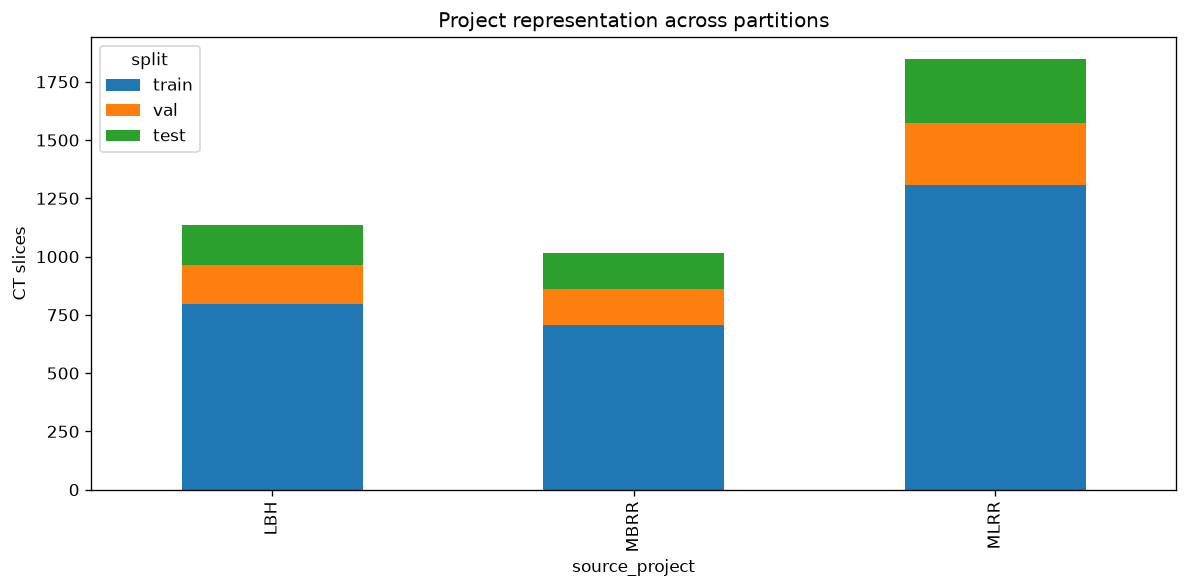

Projects are source labels, not necessarily distinct hospitals. Patients appearing at multiple sites are counted at each site.


In [4]:
inventory=manifest.groupby('split').agg(slices=('sample_id','size'),patients=('patient_id','nunique'),projects=('source_project','nunique')).reindex(['train','val','test']).reset_index()
inventory['slice_percent']=100*inventory.slices/len(manifest)
inventory['patient_percent']=100*inventory.patients/manifest.patient_id.nunique()
save_table(inventory,'partition_inventory')
site=manifest.groupby(['source_project','split']).agg(slices=('sample_id','size'),patients=('patient_id','nunique')).reset_index()
save_table(site,'project_partition_inventory')
fig,ax=plt.subplots(figsize=(10,5)); site.pivot(index='source_project',columns='split',values='slices').fillna(0).reindex(columns=['train','val','test']).plot.bar(stacked=True,ax=ax); ax.set_ylabel('CT slices'); ax.set_title('Project representation across partitions'); finish(fig,'project_partition_distribution')
print('Projects are source labels, not necessarily distinct hospitals. Patients appearing at multiple sites are counted at each site.')

## 3. Extract annotation statistics directly from masks
One pass over masks, without stacking the full cohort in memory. Jointly known counts determine co-occurrence denominators. Pooled spatial IoU is computed across jointly known slices. Missing support remains NaN.

In [5]:
scope=manifest if INCLUDE_HELDOUT_LABEL_SUMMARIES else manifest.query("split == 'train'")
records=[]; pairs={}; issues=[]
for r in tqdm(scope.itertuples(index=False),total=len(scope)):
    sid=r.sample_id
    try:
        y=np.load(DATA/MASK_FOLDER/f'{sid}.npy',allow_pickle=False)
        k=np.load(DATA/'known'/f'{sid}.npy',allow_pickle=False)
        if y.ndim!=3 or y.shape[0]!=K or k.shape!=(K,): raise ValueError('Invalid tensor shape')
        if not np.isin(y,[0,1]).all() or not np.isin(k,[0,1]).all(): raise ValueError('Nonbinary array')
        y=y.astype(bool); k=k.astype(bool); area=y.sum((1,2)); p=area>0
        if (p & ~k).any(): raise ValueError('Positive mask marked unknown')
        if MASK_FOLDER=='multilabel_masks':
            with Image.open(DATA/'images'/f'{sid}.png') as im:
                if im.size != (y.shape[2],y.shape[1]): raise ValueError('Image-mask geometry mismatch')
        for j,name in enumerate(names):
            records.append((sid,r.patient_id,r.source_project,r.split,name,bool(k[j]),bool(p[j]),int(area[j]),int(y.shape[1]*y.shape[2])))
        if r.split=='train':
            # Only pairs with two positive masks need pixel intersections.
            inter=np.zeros((K,K),dtype=np.int64)
            for i in np.flatnonzero(p):
                for j in np.flatnonzero(p & (np.arange(K)>=i)):
                    inter[i,j]=inter[j,i]=np.count_nonzero(y[i]&y[j])
            eligible=np.outer(k,k); both=np.outer(p,p)
            union=(area[:,None]+area[None,:]-inter)*eligible
            for key in ['ALL', 'PROJECT:'+r.source_project]:
                if key not in pairs: pairs[key]=[np.zeros((K,K),np.int64) for _ in range(4)]
                for dest,src in zip(pairs[key],[eligible,both,inter,union]): dest+=src
    except Exception as exc: issues.append({'sample_id':sid,'reason':str(exc)})
pd.DataFrame(issues,columns=['sample_id','reason']).to_csv(REPORT/'analysis_issues.csv',index=False)
if issues: raise RuntimeError(f'{len(issues)} invalid samples; inspect analysis_issues.csv before continuing')
long=pd.DataFrame(records,columns=['sample_id','patient_id','source_project','split','biomarker','known','positive','pixels','image_pixels'])
long['negative']=long.known & ~long.positive; long['unknown']=~long.known
train=long.query("split == 'train'").copy()
print('Validated samples:',scope.shape[0])

100%|██████████| 2810/2810 [00:55<00:00, 50.22it/s]

Validated samples: 2810


## 4. Biomarker frequencies, confirmed negatives and unknowns

,biomarker,slices,positive,known,negative,unknown,foreground_pixels,positive_percent_known,unknown_percent
0,acute_on_chronic_sdh,2810,1,1,0,2809,8199,100.0,99.964413
1,basal_ganglia_hemorrhage,2810,161,161,0,2649,489181,100.0,94.270463
2,cerebral_edema,2810,414,414,0,2396,3877058,100.0,85.266904
3,chronic_sdh,2810,1,1,0,2809,6100,100.0,99.964413
4,cortical_involvement,2810,421,421,0,2389,2407138,100.0,85.017794
5,hemorrhagic_transformation,2810,253,253,0,2557,1501171,100.0,90.996441
6,hyperdense_artery_sign,2810,25,25,0,2785,16659,100.0,99.110320
7,intracerebral_hemorrhage,2810,654,654,0,2156,2612076,100.0,76.725979
8,intraventricular_hemorrhage,2810,370,370,0,2440,1247998,100.0,86.832740
9,ischemic_infarct,2810,1403,1403,0,1407,5080539,100.0,50.071174


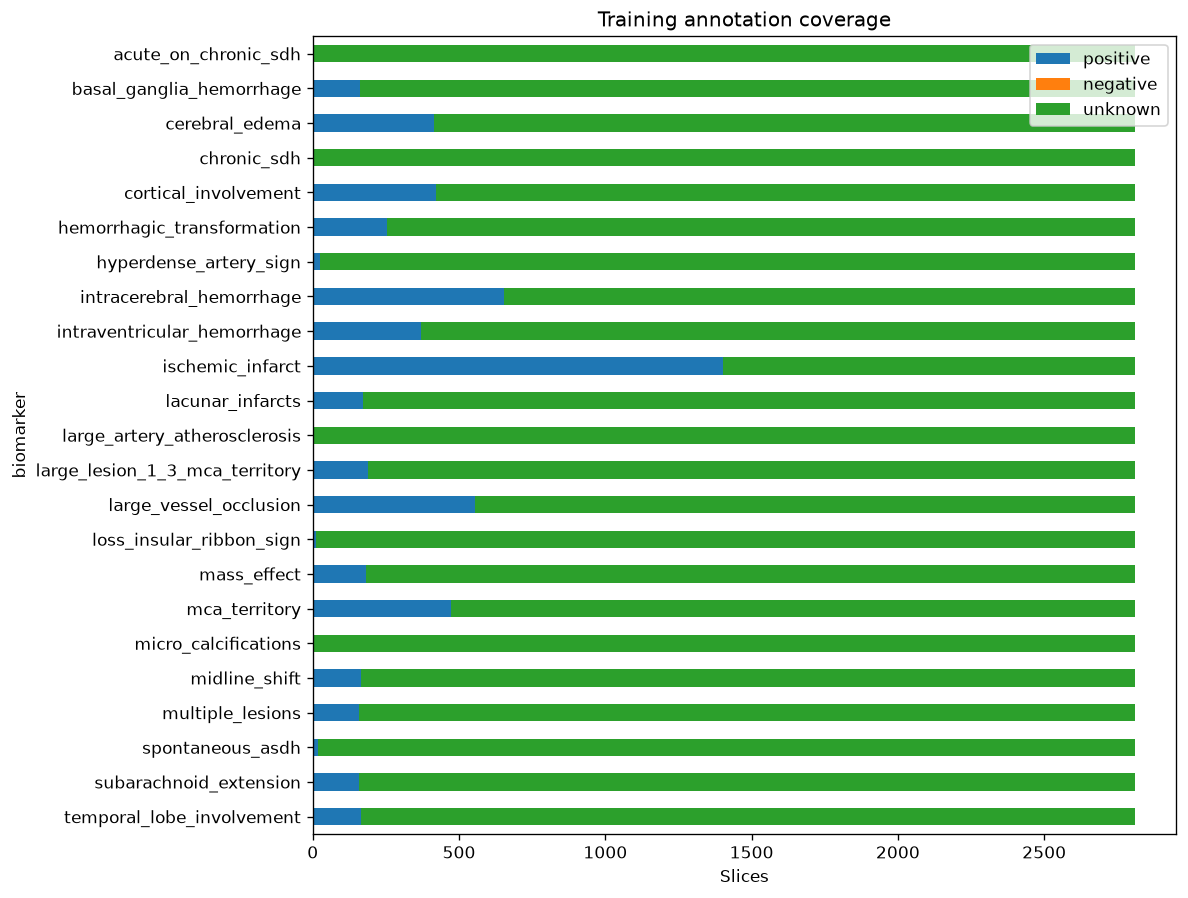

Classes with no positives: []
Classes with no confirmed negative slices: ['acute_on_chronic_sdh', 'basal_ganglia_hemorrhage', 'cerebral_edema', 'chronic_sdh', 'cortical_involvement', 'hemorrhagic_transformation', 'hyperdense_artery_sign', 'intracerebral_hemorrhage', 'intraventricular_hemorrhage', 'ischemic_infarct', 'lacunar_infarcts', 'large_artery_atherosclerosis', 'large_lesion_1_3_mca_territory', 'large_vessel_occlusion', 'loss_insular_ribbon_sign', 'mass_effect', 'mca_territory', 'micro_calcifications', 'midline_shift', 'multiple_lesions', 'spontaneous_asdh', 'subarachnoid_extension', 'temporal_lobe_involvement']


In [6]:
def summarize(data,group):
    out=data.groupby(group,observed=True).agg(slices=('sample_id','size'),positive=('positive','sum'),known=('known','sum'),negative=('negative','sum'),unknown=('unknown','sum'),foreground_pixels=('pixels','sum')).reset_index()
    out['positive_percent_known']=100*divide(out.positive,out.known)
    out['unknown_percent']=100*divide(out.unknown,out.slices)
    return out
freq=summarize(train,['biomarker']).set_index('biomarker').reindex(names).reset_index()
save_table(freq,'training_biomarker_frequency')
fig,ax=plt.subplots(figsize=(10,max(5,K*.33))); freq.set_index('biomarker')[['positive','negative','unknown']].plot.barh(stacked=True,ax=ax); ax.invert_yaxis(); ax.set_xlabel('Slices'); ax.set_title('Training annotation coverage'); finish(fig,'training_annotation_coverage')
print('Classes with no positives:',freq.loc[freq.positive.eq(0),'biomarker'].tolist())
print('Classes with no confirmed negative slices:',freq.loc[freq.negative.eq(0),'biomarker'].tolist())

## 5. Patient-level biomarker observations
A patient is observed positive if at least one included slice is positive. A patient with no observed positive is not necessarily disease-free; even fully annotated sampled slices may omit the lesion elsewhere in the scan.

In [7]:
patient=train.groupby(['patient_id','biomarker']).agg(observed_positive=('positive','max'),all_sampled_slices_known=('known','all')).reset_index()
patient['fully_known_no_observed_positive']=patient.all_sampled_slices_known & ~patient.observed_positive
patient['uncertain_no_observed_positive']=~patient.all_sampled_slices_known & ~patient.observed_positive
pt=patient.groupby('biomarker').agg(patients=('patient_id','size'),observed_positive_patients=('observed_positive','sum'),fully_known_no_observed_positive=('fully_known_no_observed_positive','sum'),uncertain_no_observed_positive=('uncertain_no_observed_positive','sum')).reindex(names).reset_index()
save_table(pt,'training_patient_observations')

,biomarker,patients,observed_positive_patients,fully_known_no_observed_positive,uncertain_no_observed_positive
0,acute_on_chronic_sdh,2810,1,0,2809
1,basal_ganglia_hemorrhage,2810,161,0,2649
2,cerebral_edema,2810,414,0,2396
3,chronic_sdh,2810,1,0,2809
4,cortical_involvement,2810,421,0,2389
5,hemorrhagic_transformation,2810,253,0,2557
6,hyperdense_artery_sign,2810,25,0,2785
7,intracerebral_hemorrhage,2810,654,0,2156
8,intraventricular_hemorrhage,2810,370,0,2440
9,ischemic_infarct,2810,1403,0,1407


## 6. Pixel-level imbalance and lesion size
Pixel areas refer to the selected mask resolution, not physical mm² or lesion volume. The background fraction is relative to the full image canvas, including padding.

,biomarker,positive_slices,median_pixels,q25_pixels,q75_pixels,median_area_percent,foreground_percent_known_canvas
0,acute_on_chronic_sdh,1,8199.0,8199.00,8199.00,3.127670,3.127670
1,basal_ganglia_hemorrhage,161,2335.0,1484.00,3938.00,0.890732,1.159054
2,cerebral_edema,414,5611.5,2688.25,10405.75,2.140617,3.572416
3,chronic_sdh,1,6100.0,6100.00,6100.00,2.326965,2.326965
4,cortical_involvement,421,2204.0,590.00,7970.00,0.840759,2.181117
5,hemorrhagic_transformation,253,2460.0,594.00,9700.00,0.938416,2.263444
6,hyperdense_artery_sign,25,715.0,449.00,880.00,0.272751,0.254196
7,intracerebral_hemorrhage,654,2659.0,1327.50,5710.75,1.014328,1.523590
8,intraventricular_hemorrhage,370,2269.5,986.25,4594.75,0.865746,1.286685
9,ischemic_infarct,1403,1884.0,531.50,4643.00,0.718689,1.381377


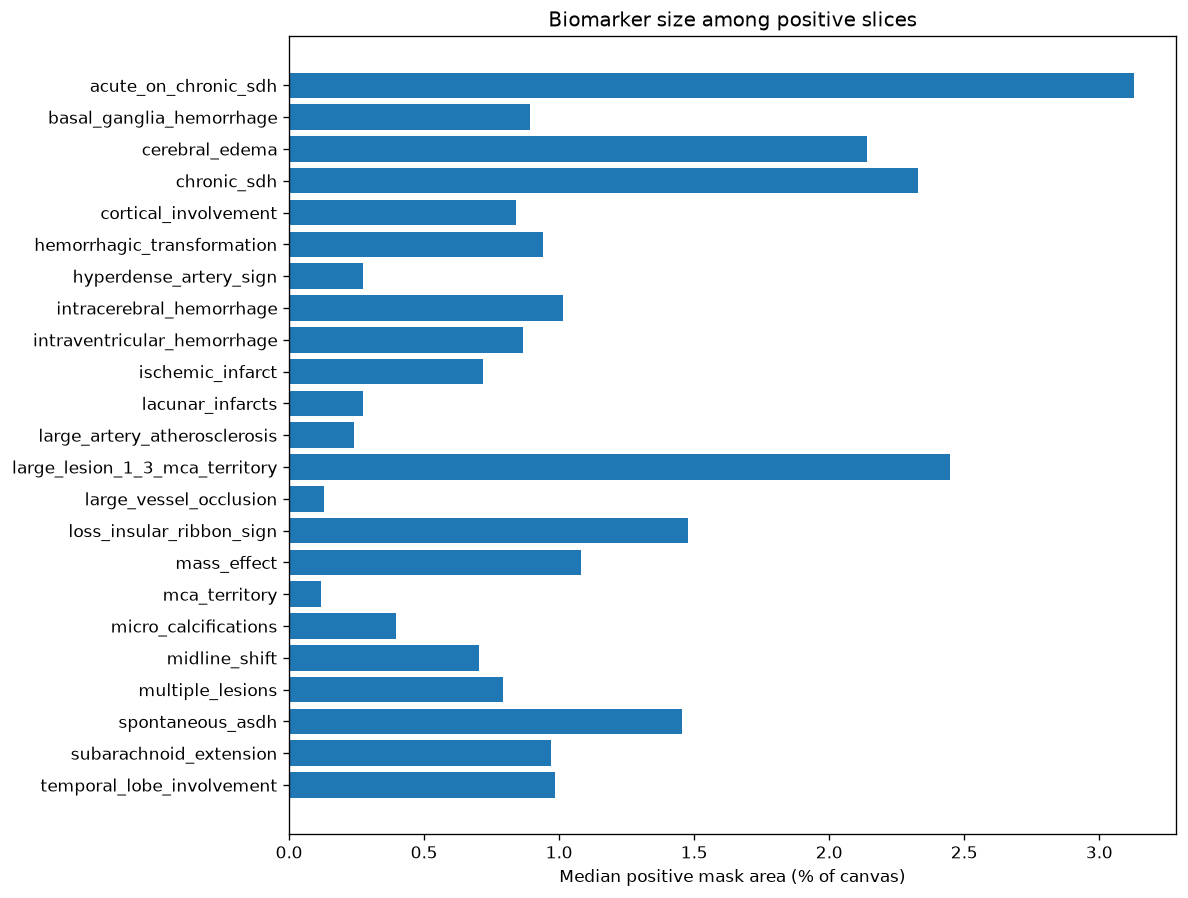

In [8]:
pos=train[train.positive].copy(); pos['area_percent']=100*pos.pixels/pos.image_pixels
size=pos.groupby('biomarker').agg(positive_slices=('pixels','size'),median_pixels=('pixels','median'),q25_pixels=('pixels',lambda x:x.quantile(.25)),q75_pixels=('pixels',lambda x:x.quantile(.75)),median_area_percent=('area_percent','median')).reindex(names).reset_index()
known_area=train.assign(known_canvas=train.image_pixels*train.known).groupby('biomarker').known_canvas.sum().reindex(names)
size['foreground_percent_known_canvas']=100*divide(freq.foreground_pixels,known_area.to_numpy())
save_table(size,'training_lesion_size')
fig,ax=plt.subplots(figsize=(10,max(5,K*.33))); ax.barh(names,size.median_area_percent); ax.invert_yaxis(); ax.set_xlabel('Median positive mask area (% of canvas)'); ax.set_title('Biomarker size among positive slices'); finish(fig,'training_lesion_size')

## 7. Co-occurrence, conditional relationships and spatial overlap
Co-occurrence = both positive / jointly known. Conditional probability = both positive / row biomarker positive among jointly known. Spatial IoU = pooled intersection / pooled union. These are descriptive associations, not causal or clinical rules.

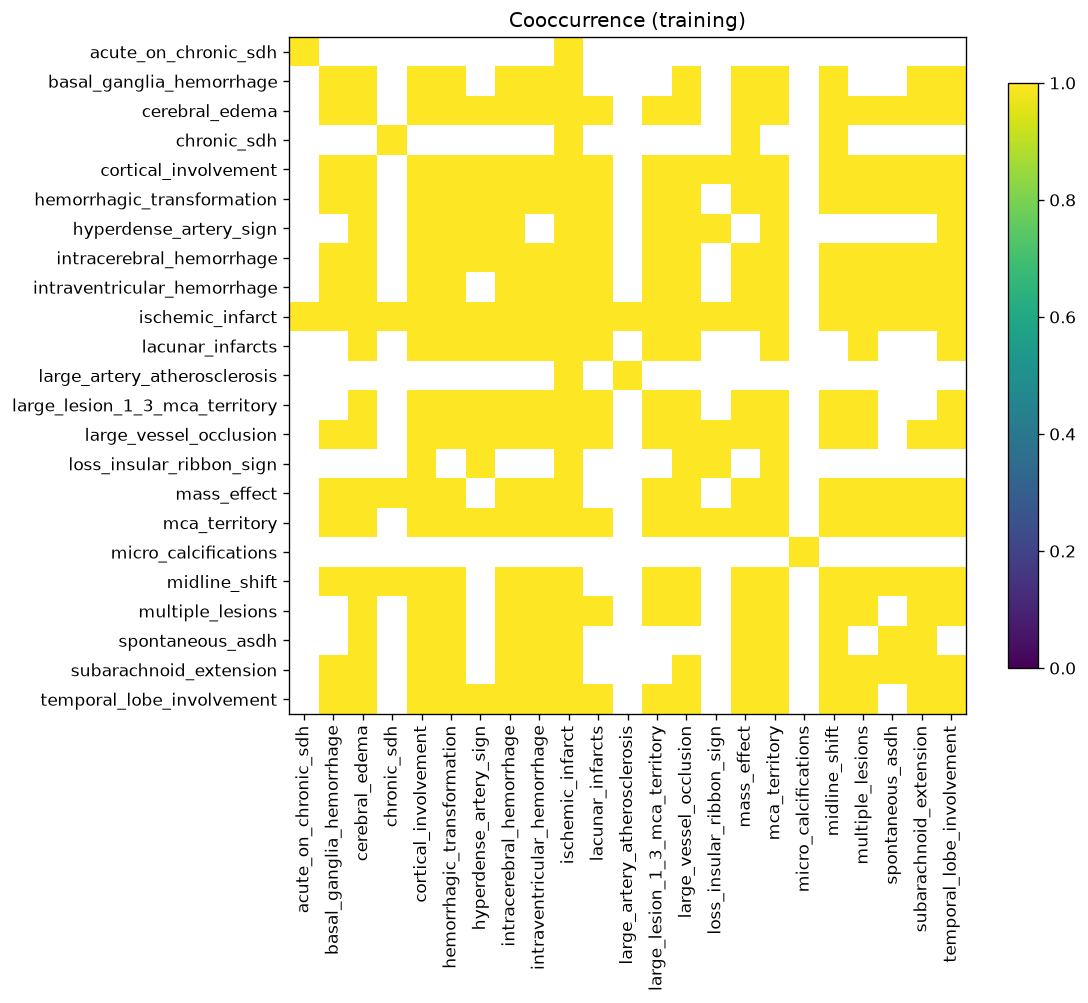

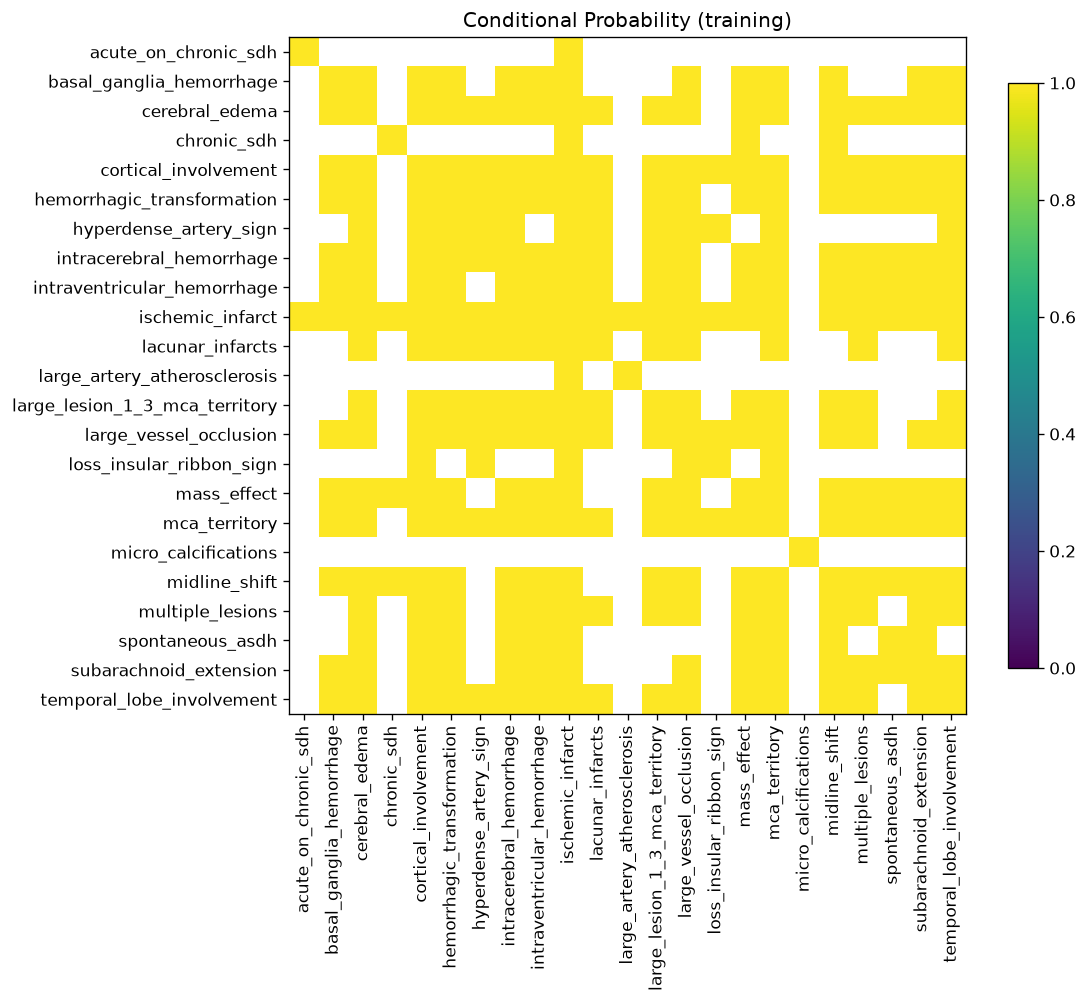

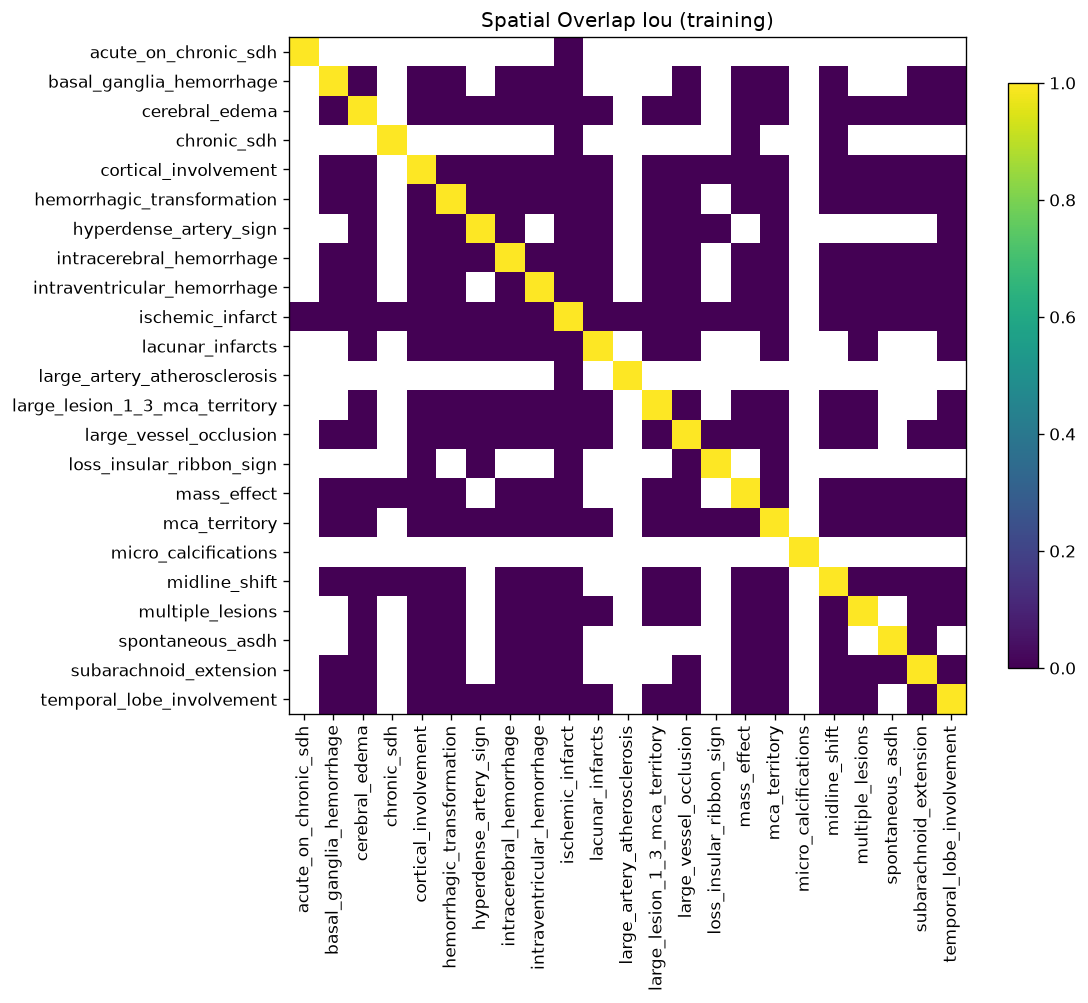

In [9]:
eligible,both,inter,union=pairs['ALL']
# row-positive and column-known support (including confirmed negatives)
P=train.pivot(index='sample_id',columns='biomarker',values='positive').reindex(columns=names).to_numpy(np.int64)
Q=train.pivot(index='sample_id',columns='biomarker',values='known').reindex(columns=names).to_numpy(np.int64)
row_support=P.T@Q
co=divide(both,eligible); conditional=divide(both,row_support); iou=divide(inter,union)
matrices={'cooccurrence':co,'conditional_probability':conditional,'spatial_overlap_iou':iou,'pair_known_counts':eligible,'pair_positive_counts':both,'conditional_support':row_support,'spatial_union_pixels':union}
def heat(mat,title,name,vmax=1):
    fig,ax=plt.subplots(figsize=(max(9,K*.42),max(7,K*.38))); im=ax.imshow(np.ma.masked_invalid(mat.astype(float)),vmin=0,vmax=vmax,aspect='equal'); ax.set_xticks(range(K),names,rotation=90); ax.set_yticks(range(K),names); ax.set_title(title); fig.colorbar(im,ax=ax,shrink=.75); finish(fig,name)
for name,mat in matrices.items(): pd.DataFrame(mat,index=names,columns=names).to_csv(REPORT/f'training_{name}.csv')
for name,mat in [('cooccurrence',co),('conditional_probability',conditional),('spatial_overlap_iou',iou)]: heat(mat,name.replace('_',' ').title()+' (training)',f'training_{name}')


## 8. Strongly supported biomarker relationships
Thresholds below are exploratory screening settings, not statistical significance tests. Report support alongside any relationship.

In [10]:
MIN_JOINT_KNOWN=20
MIN_BOTH_POSITIVE=5
rows=[]
for i in range(K):
    for j in range(i+1,K):
        rows.append(dict(biomarker_a=names[i],biomarker_b=names[j],joint_known=int(eligible[i,j]),both_positive=int(both[i,j]),cooccurrence=co[i,j],spatial_iou=iou[i,j],p_b_given_a=conditional[i,j],p_a_given_b=conditional[j,i]))
relations=pd.DataFrame(rows)
relations['supported']=(relations.joint_known>=MIN_JOINT_KNOWN)&(relations.both_positive>=MIN_BOTH_POSITIVE)
relations.to_csv(REPORT/'training_all_relationships.csv',index=False)
save_table(relations.query('supported').sort_values(['cooccurrence','both_positive'],ascending=False),'training_supported_relationships')

,biomarker_a,biomarker_b,joint_known,both_positive,cooccurrence,spatial_iou,p_b_given_a,p_a_given_b,supported
165,ischemic_infarct,large_vessel_occlusion,484,484,1.0,0.0,1.0,1.0,True
168,ischemic_infarct,mca_territory,458,458,1.0,0.0,1.0,1.0,True
210,large_vessel_occlusion,mca_territory,355,355,1.0,0.0,1.0,1.0,True
86,cortical_involvement,ischemic_infarct,344,344,1.0,0.0,1.0,1.0,True
90,cortical_involvement,large_vessel_occlusion,271,271,1.0,0.0,1.0,1.0,True
47,cerebral_edema,intracerebral_hemorrhage,254,254,1.0,0.0,1.0,1.0,True
93,cortical_involvement,mca_territory,250,250,1.0,0.0,1.0,1.0,True
103,hemorrhagic_transformation,ischemic_infarct,160,160,1.0,0.0,1.0,1.0,True
107,hemorrhagic_transformation,large_vessel_occlusion,134,134,1.0,0.0,1.0,1.0,True
174,ischemic_infarct,temporal_lobe_involvement,128,128,1.0,0.0,1.0,1.0,True


## 9. Hospital/project differences and possible domain shift

,source_project,biomarker,slices,positive,known,negative,unknown,foreground_pixels,positive_percent_known,unknown_percent
0,LBH,acute_on_chronic_sdh,796,1,1,0,795,8199,100.0,99.874372
1,LBH,basal_ganglia_hemorrhage,796,24,24,0,772,57685,100.0,96.984925
2,LBH,cerebral_edema,796,81,81,0,715,1986515,100.0,89.824121
3,LBH,chronic_sdh,796,1,1,0,795,6100,100.0,99.874372
4,LBH,cortical_involvement,796,13,13,0,783,40434,100.0,98.366834
5,LBH,hemorrhagic_transformation,796,48,48,0,748,431126,100.0,93.969849
6,LBH,hyperdense_artery_sign,796,18,18,0,778,11058,100.0,97.738693
7,LBH,intracerebral_hemorrhage,796,184,184,0,612,750951,100.0,76.884422
8,LBH,intraventricular_hemorrhage,796,122,122,0,674,340783,100.0,84.673367
9,LBH,ischemic_infarct,796,308,308,0,488,1990180,100.0,61.306533


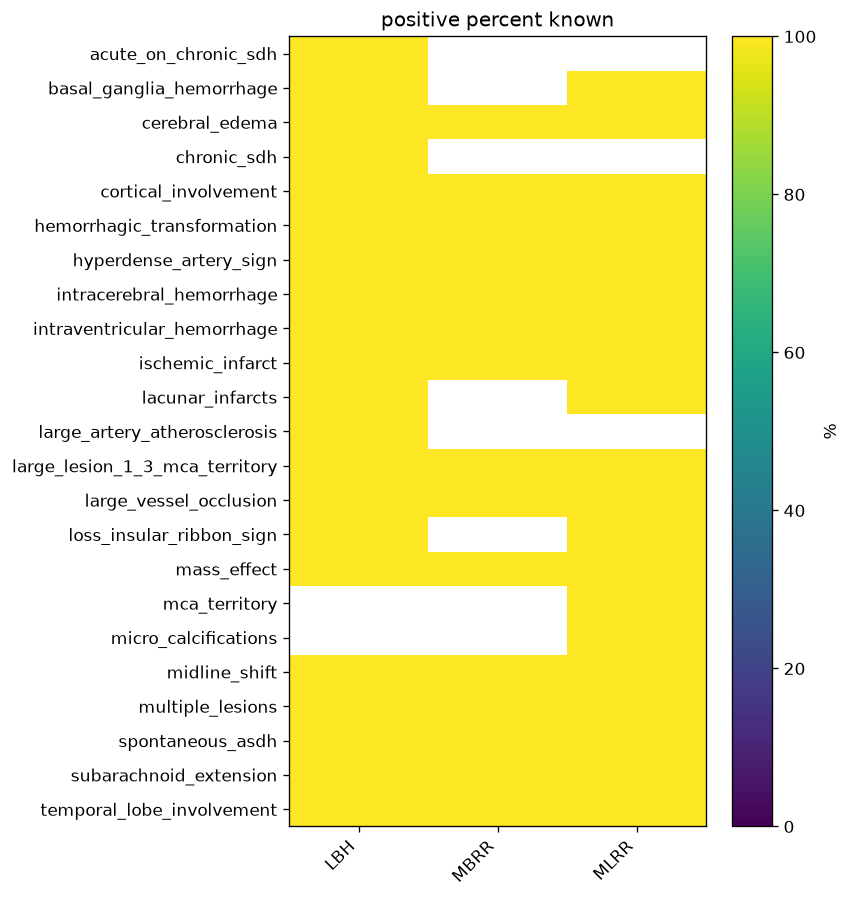

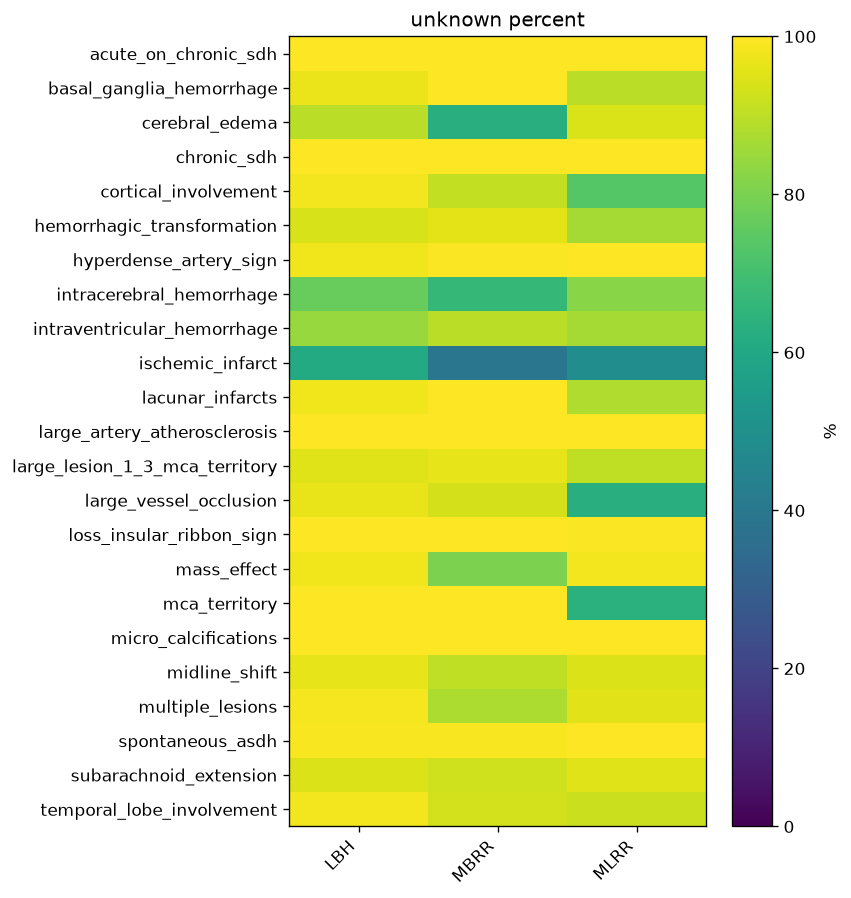

2810it [00:05, 518.09it/s]


,source_project,nonzero_mean_median,nonzero_mean_mean,nonzero_std_median,nonzero_std_mean,zero_fraction_median,zero_fraction_mean
0,LBH,140.779590,141.994572,68.010786,68.208903,0.603825,0.603808
1,MBRR,149.413155,149.969755,63.005114,64.113344,0.583639,0.594372
2,MLRR,142.382223,143.705866,61.154364,61.583077,0.528948,0.530993


In [11]:
site_freq=summarize(train,['source_project','biomarker']); save_table(site_freq,'training_project_biomarker_distribution')
for measure in ['positive_percent_known','unknown_percent']:
    table=site_freq.pivot(index='biomarker',columns='source_project',values=measure).reindex(names)
    fig,ax=plt.subplots(figsize=(max(7,len(table.columns)*1.5),max(6,K*.33))); im=ax.imshow(np.ma.masked_invalid(table.to_numpy(float)),vmin=0,vmax=100,aspect='auto'); ax.set_xticks(range(len(table.columns)),table.columns,rotation=45,ha='right'); ax.set_yticks(range(K),names); ax.set_title(measure.replace('_',' ')); fig.colorbar(im,ax=ax,label='%'); finish(fig,'project_'+measure)
# Image appearance descriptors from processed training PNGs; not HU or scanner calibration.
appearance=[]
for r in tqdm(manifest.query("split=='train'").itertuples(index=False)):
    with Image.open(DATA/'images'/f'{r.sample_id}.png') as im: a=np.asarray(im.convert('L'))
    fg=a[a>0]; appearance.append((r.source_project,float(fg.mean()) if fg.size else np.nan,float(fg.std()) if fg.size else np.nan,float((a==0).mean())))
a=pd.DataFrame(appearance,columns=['source_project','nonzero_mean','nonzero_std','zero_fraction'])
save_table(a.groupby('source_project').agg(['median','mean']).reset_index().pipe(lambda x:x.set_axis(['_'.join(c).strip('_') for c in x.columns],axis=1)),'training_project_intensity_summary')

## 10. Partition biomarker balance (optional reporting only)
Keep disabled during model development. Enable once the evaluation protocol is locked; never use test-label summaries to select architecture or hyperparameters.

In [12]:
if INCLUDE_HELDOUT_LABEL_SUMMARIES:
    save_table(summarize(long,['split','biomarker']),'all_split_biomarker_distribution')
else: print('Held-out label summaries disabled. Partition inventory already saved.')

Held-out label summaries disabled. Partition inventory already saved.


## 11. BRIDGE-Net design recommendations from training statistics
Rare classes are flagged using adjustable thresholds. No automatic class deletion, clinical rule enforcement or architecture change is made. A class without positives cannot be learned reliably; a class without confirmed negative slices may have weak negative supervision.

In [13]:
RARE_POSITIVE_SLICES=30
SMALL_MEDIAN_AREA_PERCENT=0.5
recommend=freq.merge(size[['biomarker','median_area_percent']],on='biomarker').merge(pt[['biomarker','observed_positive_patients']],on='biomarker')
def action(r):
    result=[]
    if r.positive==0: result.append('No positives: obtain annotations; report unsupported class')
    elif r.positive<RARE_POSITIVE_SLICES: result.append('Consider capped class-aware sampling and collect more positives')
    if r.negative==0: result.append('Review confirmed negative coverage')
    if r.unknown_percent>50: result.append('Review annotation completeness')
    if pd.notna(r.median_area_percent) and r.median_area_percent<SMALL_MEDIAN_AREA_PERCENT: result.append('Test high-resolution / rare-positive patches')
    return '; '.join(result) or 'Standard supervision; monitor per-class validation Dice'
recommend['recommendation']=recommend.apply(action,axis=1)
save_table(recommend,'bridge_net_design_priorities')
for filename in ['class_distribution.csv','cooccurrence.csv','spatial_overlap_iou.csv','class_weights.json','sampling_weights.csv']:
    print(filename, 'available from preprocessing' if (DATA/filename).exists() else 'not found (not required by this notebook)')


,biomarker,slices,positive,known,negative,unknown,foreground_pixels,positive_percent_known,unknown_percent,median_area_percent,observed_positive_patients,recommendation
0,acute_on_chronic_sdh,2810,1,1,0,2809,8199,100.0,99.964413,3.127670,1,Consider capped class-aware sampling and colle...
1,basal_ganglia_hemorrhage,2810,161,161,0,2649,489181,100.0,94.270463,0.890732,161,Review confirmed negative coverage; Review ann...
2,cerebral_edema,2810,414,414,0,2396,3877058,100.0,85.266904,2.140617,414,Review confirmed negative coverage; Review ann...
3,chronic_sdh,2810,1,1,0,2809,6100,100.0,99.964413,2.326965,1,Consider capped class-aware sampling and colle...
4,cortical_involvement,2810,421,421,0,2389,2407138,100.0,85.017794,0.840759,421,Review confirmed negative coverage; Review ann...
5,hemorrhagic_transformation,2810,253,253,0,2557,1501171,100.0,90.996441,0.938416,253,Review confirmed negative coverage; Review ann...
6,hyperdense_artery_sign,2810,25,25,0,2785,16659,100.0,99.110320,0.272751,25,Consider capped class-aware sampling and colle...
7,intracerebral_hemorrhage,2810,654,654,0,2156,2612076,100.0,76.725979,1.014328,654,Review confirmed negative coverage; Review ann...
8,intraventricular_hemorrhage,2810,370,370,0,2440,1247998,100.0,86.832740,0.865746,370,Review confirmed negative coverage; Review ann...
9,ischemic_infarct,2810,1403,1403,0,1407,5080539,100.0,50.071174,0.718689,1403,Review confirmed negative coverage; Review ann...


class_distribution.csv available from preprocessing
cooccurrence.csv available from preprocessing
spatial_overlap_iou.csv available from preprocessing
class_weights.json available from preprocessing
sampling_weights.csv available from preprocessing


## 12. Reproducible analysis summary
Outputs are descriptive, not model accuracy estimates. Do not claim physical lesion volume from PNG masks. Keep reports in a secure workspace.

In [14]:
summary={'dataset':str(DATA),'mask_folder':MASK_FOLDER,'classes':K,'total_slices':len(manifest),'total_patient_ids':manifest.patient_id.nunique(),'training_slices':int((manifest.split=='train').sum()),'training_patient_ids':manifest.loc[manifest.split=='train','patient_id'].nunique(),'heldout_labels_inspected':INCLUDE_HELDOUT_LABEL_SUMMARIES,'zero_positive_classes':freq.loc[freq.positive.eq(0),'biomarker'].tolist(),'zero_confirmed_negative_classes':freq.loc[freq.negative.eq(0),'biomarker'].tolist(),'supported_relationships':int(relations.supported.sum()),'thresholds':{'rare_positive_slices':RARE_POSITIVE_SLICES,'small_area_percent':SMALL_MEDIAN_AREA_PERCENT,'minimum_joint_known':MIN_JOINT_KNOWN,'minimum_both_positive':MIN_BOTH_POSITIVE}}
(REPORT/'analysis_summary.json').write_text(json.dumps(summary,indent=2))
print(json.dumps(summary,indent=2)); print('Reports:',REPORT)

{
  "dataset": "/Users/bash/Documents/Phd code/bash_phd/labelbox_export_segmentation/bridge_preprocessed_baseline",
  "mask_folder": "multilabel_masks",
  "classes": 23,
  "total_slices": 3998,
  "total_patient_ids": 3998,
  "training_slices": 2810,
  "training_patient_ids": 2810,
  "heldout_labels_inspected": false,
  "zero_positive_classes": [],
  "zero_confirmed_negative_classes": [
    "acute_on_chronic_sdh",
    "basal_ganglia_hemorrhage",
    "cerebral_edema",
    "chronic_sdh",
    "cortical_involvement",
    "hemorrhagic_transformation",
    "hyperdense_artery_sign",
    "intracerebral_hemorrhage",
    "intraventricular_hemorrhage",
    "ischemic_infarct",
    "lacunar_infarcts",
    "large_artery_atherosclerosis",
    "large_lesion_1_3_mca_territory",
    "large_vessel_occlusion",
    "loss_insular_ribbon_sign",
    "mass_effect",
    "mca_territory",
    "micro_calcifications",
    "midline_shift",
    "multiple_lesions",
    "spontaneous_asdh",
    "subarachnoid_extension",
